# TEST 3 — PRAKTIKUM CLUSTERING K-MEANS
## Pengelompokan Karakteristik Gempa Bumi Global

**Dataset:** `global_earthquakes_seismic.csv` atau `data_gempa_ringkas.csv`  
**Metode:** K-Means | **Fitur:** `mag`, `depth`, `nst`, `dmin`, `rms`, `gap`  
**Alat:** Python, Pandas, NumPy, Matplotlib, Scikit-learn, Streamlit

**Tujuan:** melakukan pemahaman dataset, EDA, preprocessing, penentuan K, clustering, evaluasi, visualisasi dan interpretasi. Dashboard interaktif Streamlit tersedia sebagai berkas **`app.py`** pada paket proyek.

> **Peringatan interpretasi:** cluster menggambarkan pola karakteristik *pengukuran seismik*, bukan prediksi gempa, penentu tsunami, atau kategori resmi bahaya gempa.

> **Sumber data:** file dataset yang diberikan untuk praktikum. Kolom-kolom serupa dengan data USGS, tetapi asal berkas persisnya belum diverifikasi. Untuk definisi beberapa atribut dapat merujuk ke https://earthquake.usgs.gov/earthquakes/feed/v1.0/csv.php.

## Persiapan — cara menjalankan notebook

1. Buka file `.ipynb` di **VS Code** (pilih kernel Python) atau unggah ke **Google Colab**.
2. Pastikan **`data_gempa_ringkas.csv`** ada di folder yang sama dengan notebook. Jika memakai Colab, unggah CSV itu ke folder `/content` melalui menu *Files*.
3. Jalankan sel secara berurutan menggunakan **Run All**.
4. Di bagian visualisasi, ganti `K_PILIHAN`, `FITUR_X`, atau `FITUR_Y` bila ingin melihat konfigurasi berbeda.
5. Notebook akan mengekspor CSV hasil standardisasi + cluster ke folder `hasil_notebook/`.

Paket ZIP menyertakan `requirements.txt`. Jika modul belum terpasang, jalankan instalasi berikut melalui terminal, bukan sebagai bagian wajib analisis: `python -m pip install pandas numpy matplotlib scikit-learn`.

In [1]:
# Langkah 0 — Mengimpor pustaka
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 110})
RANDOM_STATE = 42
FEATURES = ['mag', 'depth', 'nst', 'dmin', 'rms', 'gap']
LOG_FEATURES = ['depth', 'nst', 'dmin']
CLIP_FEATURES = ['depth', 'nst', 'dmin', 'rms', 'gap']
print('✅ Pustaka berhasil diimpor')

✅ Pustaka berhasil diimpor


## Langkah 1 — Memahami dan mengimpor dataset

Notebook akan mencoba memuat file original (25 kolom) bila tersedia, kemudian fallback ke file ringkas (15 kolom) yang sudah dibundel dalam paket. Kedua file mengandung 10.000 kejadian yang sama; enam fitur untuk clustering sama sehingga pipeline tetap konsisten. Fitur waktu, lokasi, ID, kelas turunan dan kolom teks **tidak** digunakan sebagai masukan K-Means.

In [2]:
# Pencarian dataset secara otomatis di folder proyek / Google Colab
FILENAME_OPTIONS = ['global_earthquakes_seismic.csv', 'data_gempa_ringkas.csv']
SEARCH_DIRS = [Path.cwd(), Path.cwd() / 'Praktikum_Clustering_KMeans',
               Path('/content'), Path('/mnt/data'), Path('/mnt/data/Praktikum_Clustering_KMeans')]
file_data = next((folder / name
                  for name in FILENAME_OPTIONS for folder in SEARCH_DIRS
                  if (folder / name).is_file()), None)
if file_data is None:
    raise FileNotFoundError(
        'File dataset belum ditemukan. Letakkan data_gempa_ringkas.csv di folder yang sama '
        'dengan notebook (di Google Colab: unggah ke /content), kemudian jalankan lagi.'
    )
raw = pd.read_csv(file_data, low_memory=False)
print('Dataset:', file_data)
print('Ukuran (baris, kolom):', raw.shape)
print('Nama kolom:', raw.columns.tolist())
print('\nTipe data:')
print(raw.dtypes.to_string())
print('\nContoh 5 baris:')
display(raw.head())

Dataset: /Users/mochammadmarillivio/Downloads/Praktikum_Clustering_KMeans /data_gempa_ringkas.csv
Ukuran (baris, kolom): (10000, 15)
Nama kolom: ['id', 'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place', 'tsunami', 'sig', 'nst', 'dmin', 'rms', 'gap', 'type']

Tipe data:
id            object
time           int64
latitude     float64
longitude    float64
depth        float64
mag          float64
magType       object
place         object
tsunami        int64
sig            int64
nst            int64
dmin         float64
rms          float64
gap          float64
type          object

Contoh 5 baris:


,id,time,latitude,longitude,depth,mag,magType,place,tsunami,sig,nst,dmin,rms,gap,type
0,us6000u20i,1791884908205,-9.9266,118.8246,35.0,4.5,mb,"71 km SW of Tambolaka, Indonesia",0,312,28,4.966,0.67,123.0,earthquake
1,us6000u20g,1791884472899,38.5166,68.8922,10.0,4.7,mb,"9 km NE of Boshkengash, Tajikistan",0,340,64,1.821,0.70,62.0,earthquake
2,us6000u207,1791880708325,-28.5560,-12.5205,10.0,5.3,mb,southern Mid-Atlantic Ridge,0,432,37,27.968,1.03,63.0,earthquake
3,us6000u1zh,1791873544944,7.7685,-81.4531,10.0,4.7,mb,"14 km WNW of Río Grande, Panama",0,340,37,2.117,0.80,140.0,earthquake
4,us6000u1zc,1791871284155,19.6853,120.7047,10.0,4.7,mb,"124 km N of Pagudpud, Philippines",0,340,42,3.136,0.95,132.0,earthquake


In [3]:
print('Ringkasan statistik semua fitur numerik:')
display(raw.select_dtypes(include='number').describe().T.round(3))
print('Jumlah nilai kosong keseluruhan:', int(raw.isna().sum().sum()))
print('Jumlah baris duplikat:', int(raw.duplicated().sum()))
print('Jenis kejadian:\n', raw['type'].value_counts().to_string())

required = set(FEATURES + ['type', 'id'])
if not required.issubset(raw.columns):
    raise ValueError('Fitur yang diperlukan tidak ada: ' + str(sorted(required - set(raw.columns))))
print('\nFitur clustering:', FEATURES)

Ringkasan statistik semua fitur numerik:


,count,mean,std,min,25%,50%,75%,max
time,10000.0,1.771917e+12,1.169027e+10,1.753890e+12,1.760858e+12,1.772140e+12,1.782527e+12,1.791885e+12
latitude,10000.0,7.829000e+00,3.190900e+01,-6.746900e+01,-1.544900e+01,5.195000e+00,3.838600e+01,8.506400e+01
longitude,10000.0,6.165000e+01,1.164410e+02,-1.799970e+02,-3.262900e+01,1.250270e+02,1.522650e+02,1.799900e+02
depth,10000.0,5.616600e+01,1.015770e+02,0.000000e+00,1.000000e+01,1.100000e+01,5.699300e+01,6.695560e+02
mag,10000.0,4.812000e+00,3.670000e-01,4.500000e+00,4.500000e+00,4.700000e+00,5.000000e+00,7.800000e+00
tsunami,10000.0,8.000000e-03,9.100000e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
sig,10000.0,3.625630e+02,8.791600e+01,3.120000e+02,3.130000e+02,3.400000e+02,3.850000e+02,2.910000e+03
nst,10000.0,6.678200e+01,4.685600e+01,0.000000e+00,3.400000e+01,5.500000e+01,8.500000e+01,5.660000e+02
dmin,10000.0,4.128000e+00,5.263000e+00,0.000000e+00,1.498000e+00,2.494000e+00,4.651000e+00,5.530700e+01
rms,10000.0,7.620000e-01,2.200000e-01,1.200000e-01,6.100000e-01,7.400000e-01,9.000000e-01,3.900000e+00


Jumlah nilai kosong keseluruhan: 0
Jumlah baris duplikat: 0
Jenis kejadian:
 type
earthquake    9998
landslide        2

Fitur clustering: ['mag', 'depth', 'nst', 'dmin', 'rms', 'gap']


## Langkah 2 — Exploratory Data Analysis (EDA)

Hanya kejadian `earthquake` digunakan. Duplikat berdasarkan ID kejadian dihapus untuk menghindari penggandaan satu gempa. Histogram menggambarkan distribusi, boxplot memperlihatkan sebaran serta titik ekstrem, dan korelasi Pearson memperlihatkan asosiasi linear antarfitur.

In [4]:
gempa = (raw.loc[raw['type'].eq('earthquake')]
         .drop_duplicates(subset=['id'], keep='first').reset_index(drop=True).copy())
for kolom in FEATURES:
    gempa[kolom] = pd.to_numeric(gempa[kolom], errors='coerce')

print('Data sumber:', len(raw))
print('Data gempa setelah filter/deduplikasi:', len(gempa))
print('Missing nilai per fitur:')
display(gempa[FEATURES].isna().sum().to_frame('missing'))
display(gempa[FEATURES].describe().T.round(3))

Data sumber: 10000
Data gempa setelah filter/deduplikasi: 9998
Missing nilai per fitur:


,missing
mag,0
depth,0
nst,0
dmin,0
rms,0
gap,0


,count,mean,std,min,25%,50%,75%,max
mag,9998.0,4.812,0.367,4.500,4.500,4.700,5.000,7.800
depth,9998.0,56.177,101.584,1.181,10.000,11.000,56.998,669.556
nst,9998.0,66.795,46.851,0.000,34.000,55.500,85.000,566.000
dmin,9998.0,4.129,5.263,0.000,1.499,2.495,4.651,55.307
rms,9998.0,0.762,0.218,0.120,0.610,0.740,0.900,1.640
gap,9998.0,100.026,42.764,0.000,68.000,98.000,129.000,275.000


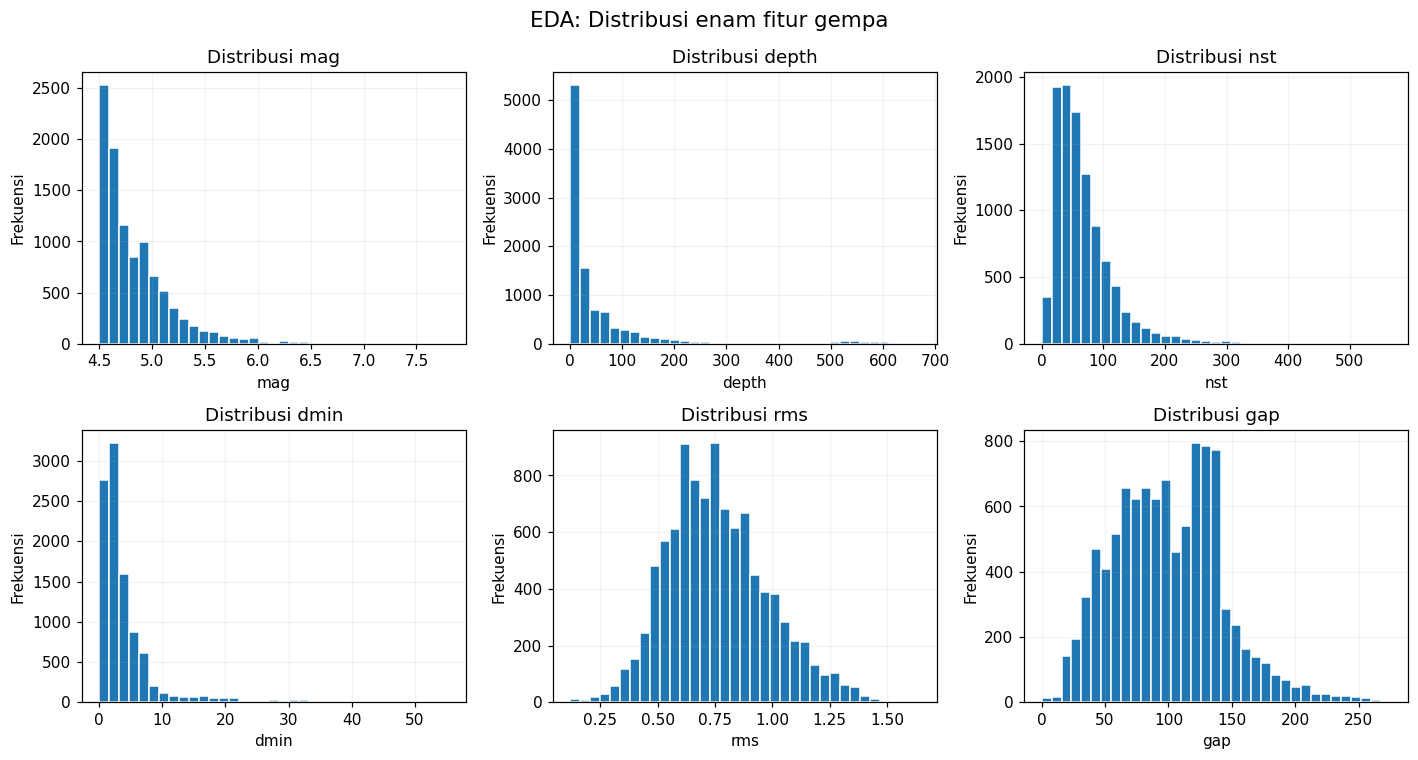

ANALISIS HISTOGRAM
- mag: rata-rata=4.812; median=4.700; skewness=2.25; distribusi cenderung miring kanan.
- depth: rata-rata=56.177; median=11.000; skewness=3.76; distribusi cenderung miring kanan.
- nst: rata-rata=66.795; median=55.500; skewness=2.08; distribusi cenderung miring kanan.
- dmin: rata-rata=4.129; median=2.495; skewness=3.78; distribusi cenderung miring kanan.
- rms: rata-rata=0.762; median=0.740; skewness=0.42; distribusi relatif tidak menceng kuat.
- gap: rata-rata=100.026; median=98.000; skewness=0.43; distribusi relatif tidak menceng kuat.


In [5]:
# Visualisasi 1 — histogram seluruh fitur, diikuti analisis tertulis
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES):
    ax.hist(gempa[col].dropna(), bins=35, edgecolor='white')
    ax.set_title('Distribusi ' + col)
    ax.set_xlabel(col)
    ax.set_ylabel('Frekuensi')
    ax.grid(alpha=0.15)
fig.suptitle('EDA: Distribusi enam fitur gempa', fontsize=14)
plt.tight_layout(); plt.show()

print('ANALISIS HISTOGRAM')
for col in FEATURES:
    s = gempa[col].dropna()
    skew = s.skew()
    bentuk = 'cenderung miring kanan' if skew > 0.5 else ('cenderung miring kiri' if skew < -0.5 else 'relatif tidak menceng kuat')
    print(f'- {col}: rata-rata={s.mean():.3f}; median={s.median():.3f}; skewness={skew:.2f}; distribusi {bentuk}.')

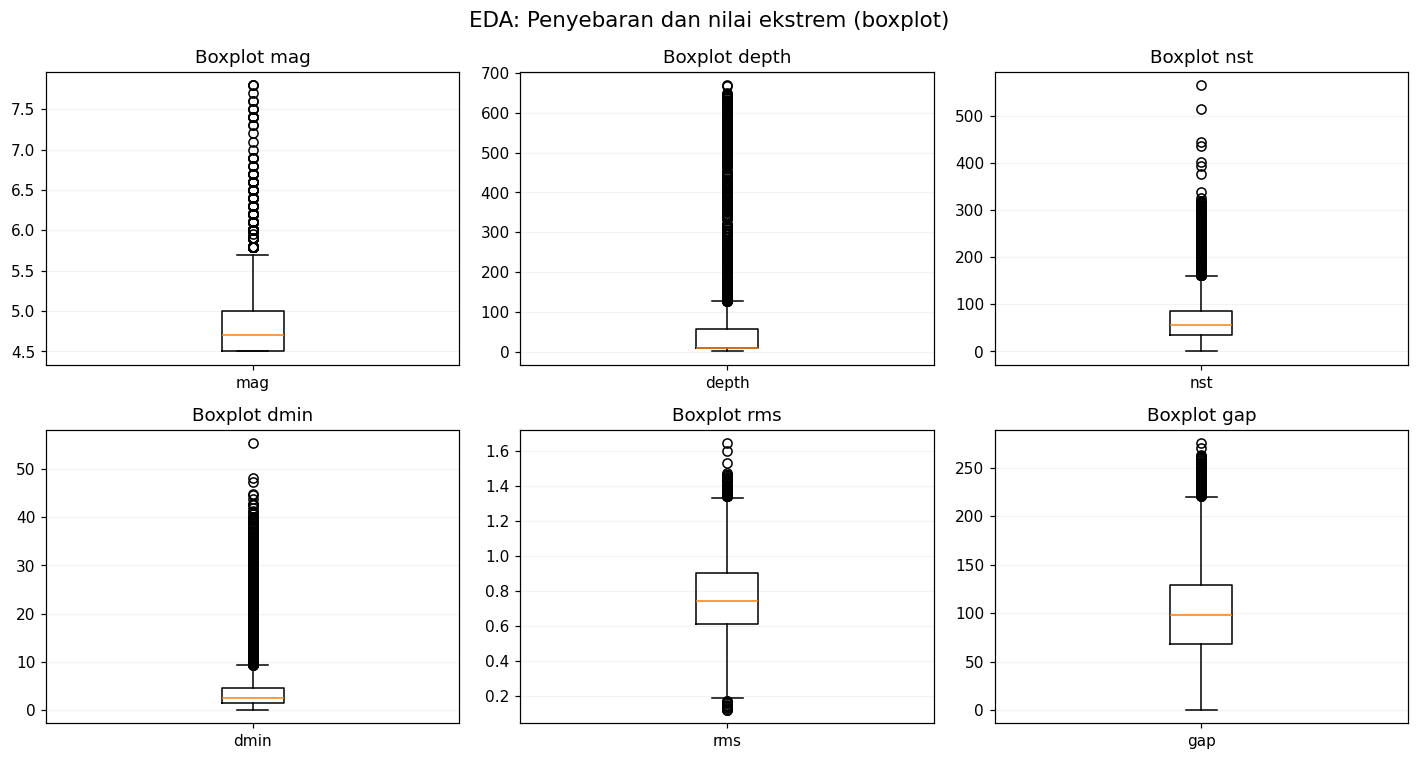

ANALISIS BOXPLOT (aturan 1,5 × IQR)
- mag: 280 nilai di luar batas boxplot; tidak serta-merta dianggap salah.
- depth: 994 nilai di luar batas boxplot; tidak serta-merta dianggap salah.
- nst: 447 nilai di luar batas boxplot; tidak serta-merta dianggap salah.
- dmin: 741 nilai di luar batas boxplot; tidak serta-merta dianggap salah.
- rms: 105 nilai di luar batas boxplot; tidak serta-merta dianggap salah.
- gap: 100 nilai di luar batas boxplot; tidak serta-merta dianggap salah.
Catatan: gempa ekstrem mungkin kejadian riil, sehingga tidak langsung dihapus.


In [6]:
# Visualisasi 2 — boxplot seluruh fitur dan ringkasan titik di luar 1.5 IQR
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES):
    ax.boxplot(gempa[col].dropna().values, tick_labels=[col], showfliers=True)
    ax.set_title('Boxplot ' + col)
    ax.grid(axis='y', alpha=0.15)
fig.suptitle('EDA: Penyebaran dan nilai ekstrem (boxplot)', fontsize=14)
plt.tight_layout(); plt.show()

print('ANALISIS BOXPLOT (aturan 1,5 × IQR)')
for col in FEATURES:
    s = gempa[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    outliers = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
    print(f'- {col}: {outliers} nilai di luar batas boxplot; tidak serta-merta dianggap salah.')
print('Catatan: gempa ekstrem mungkin kejadian riil, sehingga tidak langsung dihapus.')

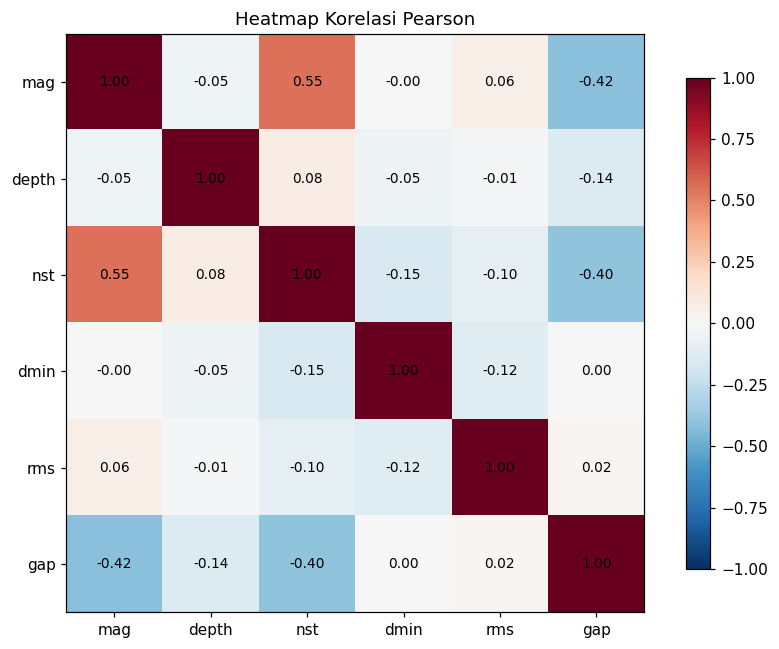

ANALISIS HEATMAP: pasangan fitur dengan |r| tertinggi adalah mag dan nst (r=0.551).
Korelasi bukan hubungan sebab-akibat; pengaruh fitur pada K-Means juga dipengaruhi jarak dan skala.


In [7]:
# Visualisasi 3 — korelasi Pearson (data sebelum transformasi)
corr = gempa[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 6))
img = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(FEATURES)), FEATURES)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(img, ax=ax, shrink=0.85)
ax.set_title('Heatmap Korelasi Pearson')
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pasangan = upper.abs().idxmax()
r_tertinggi = corr.loc[pasangan[0], pasangan[1]]
print(f'ANALISIS HEATMAP: pasangan fitur dengan |r| tertinggi adalah {pasangan[0]} dan {pasangan[1]} (r={r_tertinggi:.3f}).')
print('Korelasi bukan hubungan sebab-akibat; pengaruh fitur pada K-Means juga dipengaruhi jarak dan skala.')

## Langkah 3 — Pra-pemrosesan

1. Missing values numerik diimputasi menggunakan **median fitur** (bila ada).
2. Nilai `depth`, `nst`, `dmin` ditransformasikan dengan `log1p` untuk meredam kemencengan (nilai negatif dijadikan nol hanya untuk fitur transformasi ini).
3. Setelah transformasi, nilai pada `depth`, `nst`, `dmin`, `rms`, `gap` dibatasi ke persentil 1–99 (**winsorisasi**, bukan menghapus baris); `mag` tidak dipotong.
4. Enam fitur distandardisasi menggunakan `StandardScaler` agar perbedaan satuan tidak mendominasi jarak Euclidean.

**Penting:** nilai mentah tetap disimpan untuk interpretasi. Dataset yang diekspor akan memiliki kolom fitur `_scaled` dan `cluster`.

In [8]:
# Penanganan nilai kosong
missing_awal = gempa[FEATURES].isna().sum()
median_fitur = gempa[FEATURES].median(numeric_only=True)
gempa[FEATURES] = gempa[FEATURES].fillna(median_fitur)
if gempa[FEATURES].isna().any().any():
    raise ValueError('Masih terdapat NaN sesudah imputasi. Periksa fitur numerik.')

# log1p dan pembatasan kuantil (tidak menghapus baris)
transformed = gempa[FEATURES].copy()
for col in LOG_FEATURES:
    transformed[col] = np.log1p(transformed[col].clip(lower=0))

batas = {}
for col in CLIP_FEATURES:
    q01, q99 = transformed[col].quantile([0.01, 0.99])
    transformed[col] = transformed[col].clip(q01, q99)
    batas[col] = (float(q01), float(q99))

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(transformed), columns=FEATURES, index=gempa.index)
print('Missing sebelum imputasi:', missing_awal.to_dict())
print('Ukuran hasil standardisasi:', X.shape)
print('Rerata fitur standardized (~0):\n', X.mean().round(4).to_string())
print('Deviasi standar population (~1):\n', X.std(ddof=0).round(4).to_string())
display(X.head())

Missing sebelum imputasi: {'mag': 0, 'depth': 0, 'nst': 0, 'dmin': 0, 'rms': 0, 'gap': 0}
Ukuran hasil standardisasi: (9998, 6)
Rerata fitur standardized (~0):
 mag      0.0
depth   -0.0
nst      0.0
dmin    -0.0
rms      0.0
gap      0.0
Deviasi standar population (~1):
 mag      1.0
depth    1.0
nst      1.0
dmin     1.0
rms      1.0
gap      1.0


,mag,depth,nst,dmin,rms,gap
0,-0.849468,0.268116,-1.025674,0.643756,-0.429774,0.550224
1,-0.304831,-0.823372,0.254027,-0.501202,-0.290141,-0.901871
2,1.329082,-0.823372,-0.597110,3.059245,1.245818,-0.878066
3,-0.304831,-0.823372,-0.597110,-0.348671,0.175301,0.954906
4,-0.304831,-0.823372,-0.401111,0.083728,0.873464,0.764468


## Langkah 4 — Penentuan K dan penerapan K-Means

Uji **K=2 sampai 8** dengan `random_state=42` dan `n_init=10`. Inertia (SSE) dihitung dari **seluruh baris**. Untuk menghemat waktu pada notebook/laptop, Silhouette dihitung pada **1.200 sampel tetap yang sama untuk setiap K** setelah model dilatih pada seluruh data. Dengan demikian skor yang diperoleh merupakan **estimasi Silhouette sampel**, bukan Silhouette populasi penuh. Nilai K dipilih berdasarkan skor Silhouette tertinggi dalam rentang ini; Elbow digunakan sebagai pertimbangan tambahan.

In [9]:
# Evaluasi K=2..8 (samakan dengan dashboard Streamlit dan file CSV hasil)
DAFTAR_K = range(2, 9)
idx_sampel = np.random.default_rng(RANDOM_STATE).choice(
    len(X), size=min(1200, len(X)), replace=False
)
metrics = []
model_dict = {}
for k in DAFTAR_K:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, max_iter=300)
    label_k = km.fit_predict(X)
    score = silhouette_score(X.iloc[idx_sampel], label_k[idx_sampel])
    metrics.append({'K': k, 'Inertia (SSE)': km.inertia_, 'Silhouette Score': score})
    model_dict[k] = km

evaluasi = pd.DataFrame(metrics)
K_OPTIMAL = int(evaluasi.loc[evaluasi['Silhouette Score'].idxmax(), 'K'])
print('Hasil evaluasi beberapa K:')
display(evaluasi.round(4))
print('K terbaik berdasarkan Silhouette sampel =', K_OPTIMAL)

Hasil evaluasi beberapa K:


,K,Inertia (SSE),Silhouette Score
0,2,47685.5460,0.2050
1,3,41203.3273,0.1820
2,4,36602.3920,0.1703
3,5,33299.0083,0.1653
4,6,30730.6571,0.1552
5,7,28984.0715,0.1578
6,8,27562.7438,0.1615


K terbaik berdasarkan Silhouette sampel = 2


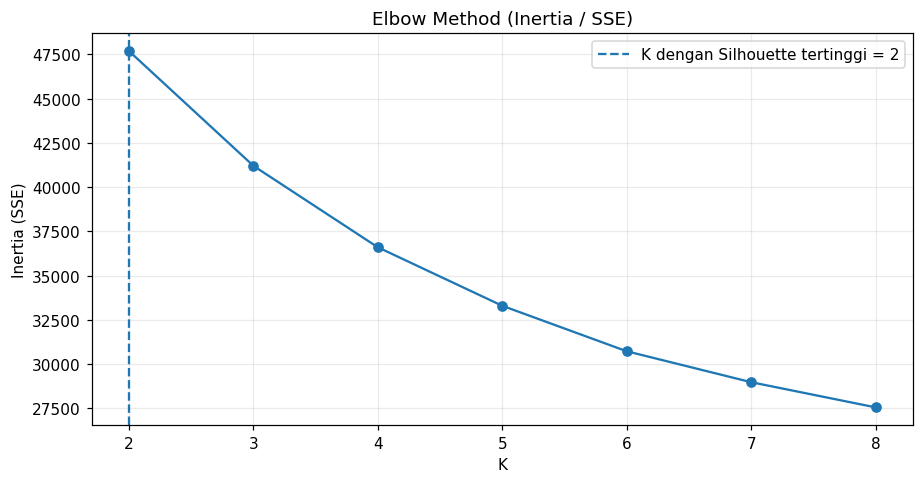

ANALISIS ELBOW: Inertia menurun saat K bertambah; ini wajar karena lebih banyak centroid membuat cluster lebih kompak.
Titik siku perlu dilihat dari perubahan kemiringan grafik, tidak otomatis sama dengan K optimal Silhouette.


In [10]:
# Visualisasi 4 — Elbow Curve dan analisis
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(evaluasi['K'], evaluasi['Inertia (SSE)'], marker='o')
ax.axvline(K_OPTIMAL, linestyle='--', label=f'K dengan Silhouette tertinggi = {K_OPTIMAL}')
ax.set_title('Elbow Method (Inertia / SSE)')
ax.set_xlabel('K'); ax.set_ylabel('Inertia (SSE)')
ax.grid(alpha=0.25); ax.legend(); plt.tight_layout(); plt.show()

print('ANALISIS ELBOW: Inertia menurun saat K bertambah; ini wajar karena lebih banyak centroid membuat cluster lebih kompak.')
print('Titik siku perlu dilihat dari perubahan kemiringan grafik, tidak otomatis sama dengan K optimal Silhouette.')

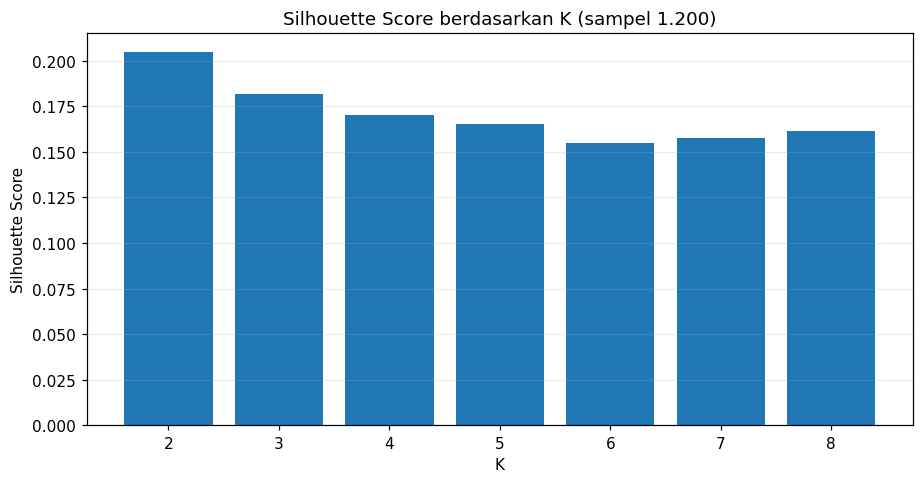

ANALISIS SILHOUETTE: skor tertinggi = 0.2050 pada K=2.
Pemisahan cluster cenderung lemah/tumpang tindih; gunakan interpretasi eksploratif, bukan kategori definitif.


In [11]:
# Visualisasi 5 — Silhouette Score dan analisis
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.bar(evaluasi['K'].astype(str), evaluasi['Silhouette Score'])
ax.set_title('Silhouette Score berdasarkan K (sampel 1.200)')
ax.set_xlabel('K'); ax.set_ylabel('Silhouette Score')
ax.grid(axis='y', alpha=0.25); plt.tight_layout(); plt.show()
best_score = float(evaluasi.loc[evaluasi['K'].eq(K_OPTIMAL), 'Silhouette Score'].iloc[0])
print(f'ANALISIS SILHOUETTE: skor tertinggi = {best_score:.4f} pada K={K_OPTIMAL}.')
if best_score < 0.25:
    print('Pemisahan cluster cenderung lemah/tumpang tindih; gunakan interpretasi eksploratif, bukan kategori definitif.')
elif best_score < 0.5:
    print('Pemisahan cluster masih sedang; beberapa data mungkin saling tumpang tindih.')
else:
    print('Pemisahan cluster relatif lebih baik, tetapi tetap perlu interpretasi substantif.')

In [12]:
# Model final — nilai default sama dengan hasil proyek, tetapi dapat diubah sendiri
K_PILIHAN = K_OPTIMAL  # contoh manual: ubah menjadi 3 atau 4 lalu jalankan ulang sel ini dan sel setelahnya
if K_PILIHAN not in model_dict:
    raise ValueError('Pilih K antara 2 dan 8.')
model_final = model_dict[K_PILIHAN]
gempa['cluster'] = model_final.labels_.astype(int)
print('K dipilih:', K_PILIHAN)
print('Inertia final:', round(float(model_final.inertia_), 3))
print('Jumlah setiap cluster:')
display(gempa['cluster'].value_counts().sort_index().rename_axis('cluster').to_frame('jumlah'))

K dipilih: 2
Inertia final: 47685.546
Jumlah setiap cluster:


,jumlah
cluster,
0,3940
1,6058


## Langkah 5 — Evaluasi dan analisis karakteristik setiap cluster

Interpretasi menggunakan **satuan asli** (misalnya kedalaman dalam kilometer) agar bermakna. Sebagai pengingat, K-Means menggunakan enam fitur yang sudah ditransformasikan dan distandardisasi. Label 0, 1, ... hanyalah identitas matematis; urutannya tidak menyatakan tingkat risiko.

In [13]:
# Rata-rata, median, jumlah dan proporsi per cluster
profil = gempa.groupby('cluster')[FEATURES].mean().round(3)
median_cluster = gempa.groupby('cluster')[FEATURES].median().round(3)
jumlah = gempa.groupby('cluster').size().rename('jumlah')
persen = (jumlah / len(gempa) * 100).rename('persentase (%)')
ringkasan_cluster = pd.concat([jumlah, persen, profil], axis=1).round(3)
print('Rata-rata tiap cluster (skala asli):')
display(ringkasan_cluster)
print('Median tiap cluster (skala asli):')
display(median_cluster)

rerata_global = gempa[FEATURES].mean()
print('\nANALISIS KARAKTERISTIK CLUSTER')
for c, r in ringkasan_cluster.iterrows():
    lebih_tinggi = [f for f in FEATURES if r[f] > rerata_global[f]*1.05]
    lebih_rendah = [f for f in FEATURES if r[f] < rerata_global[f]*0.95]
    print(f'- Cluster {c}: {int(r["jumlah"]):,} peristiwa ({r["persentase (%)"]:.1f}%).')
    print('  Fitur di atas rerata keseluruhan:', ', '.join(lebih_tinggi) or 'tidak ada yang dominan')
    print('  Fitur di bawah rerata keseluruhan:', ', '.join(lebih_rendah) or 'tidak ada yang dominan')
print('Catatan: kata "lebih tinggi" adalah perbandingan rerata data sampel, bukan ukuran bahaya.')

Rata-rata tiap cluster (skala asli):


,jumlah,persentase (%),mag,depth,nst,dmin,rms,gap
cluster,,,,,,,,
0,3940,39.408,5.077,76.980,103.715,3.352,0.758,68.419
1,6058,60.592,4.639,42.647,42.783,4.634,0.765,120.583


Median tiap cluster (skala asli):


,mag,depth,nst,dmin,rms,gap
cluster,,,,,,
0,5.0,33.98,92.0,2.184,0.73,64.0
1,4.6,10.00,39.0,2.758,0.75,122.0



ANALISIS KARAKTERISTIK CLUSTER
- Cluster 0: 3,940 peristiwa (39.4%).
  Fitur di atas rerata keseluruhan: mag, depth, nst
  Fitur di bawah rerata keseluruhan: dmin, gap
- Cluster 1: 6,058 peristiwa (60.6%).
  Fitur di atas rerata keseluruhan: dmin, gap
  Fitur di bawah rerata keseluruhan: depth, nst
Catatan: kata "lebih tinggi" adalah perbandingan rerata data sampel, bukan ukuran bahaya.


## Langkah 6 — Visualisasi hasil cluster

Scatter plot dua fitur pada skala asli memperlihatkan pemisahan pada proyeksi dua variabel. Karena K-Means menggunakan **enam** fitur, hasil bisa tampak tumpang tindih dalam grafik dua dimensi. PCA tambahan merangkum variasi fitur terstandardisasi menjadi dua komponen, bukan mengganti algoritma K-Means.

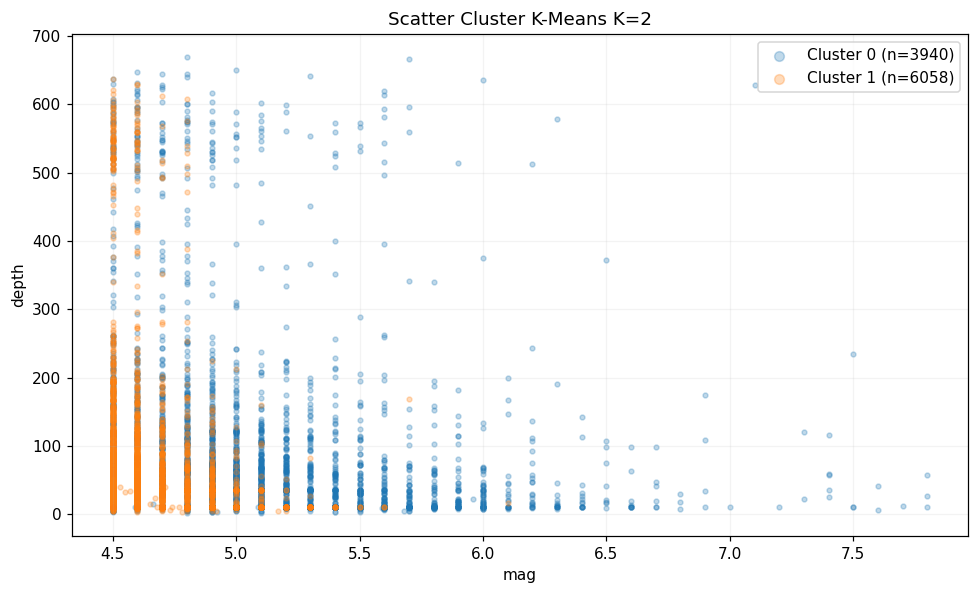

ANALISIS SCATTER: setiap titik merupakan satu kejadian gempa, dan warnanya menunjukkan cluster K-Means K=2.
Perhatikan perbedaan pola dan area yang bertumpang tindih pada dua fitur terpilih.
Label dibuat menggunakan semua 6 fitur terstandardisasi, bukan hanya dua sumbu grafik.


In [14]:
# Visualisasi 6 — scatter plot dua fitur yang dapat dipilih
FITUR_X = 'mag'    # ganti dengan: depth, nst, dmin, rms, gap
FITUR_Y = 'depth'  # pilih fitur yang berbeda dari FITUR_X
if FITUR_X not in FEATURES or FITUR_Y not in FEATURES or FITUR_X == FITUR_Y:
    raise ValueError('FITUR_X dan FITUR_Y harus merupakan dua fitur berbeda dari daftar FEATURES.')

fig, ax = plt.subplots(figsize=(9, 5.5))
for cluster, subset in gempa.groupby('cluster'):
    ax.scatter(subset[FITUR_X], subset[FITUR_Y], alpha=0.28, s=10,
               label=f'Cluster {cluster} (n={len(subset)})')
ax.set_title(f'Scatter Cluster K-Means K={K_PILIHAN}')
ax.set_xlabel(FITUR_X); ax.set_ylabel(FITUR_Y)
ax.legend(markerscale=2); ax.grid(alpha=0.15); plt.tight_layout(); plt.show()

print(f'ANALISIS SCATTER: setiap titik merupakan satu kejadian gempa, dan warnanya menunjukkan cluster K-Means K={K_PILIHAN}.')
print('Perhatikan perbedaan pola dan area yang bertumpang tindih pada dua fitur terpilih.')
print('Label dibuat menggunakan semua 6 fitur terstandardisasi, bukan hanya dua sumbu grafik.')

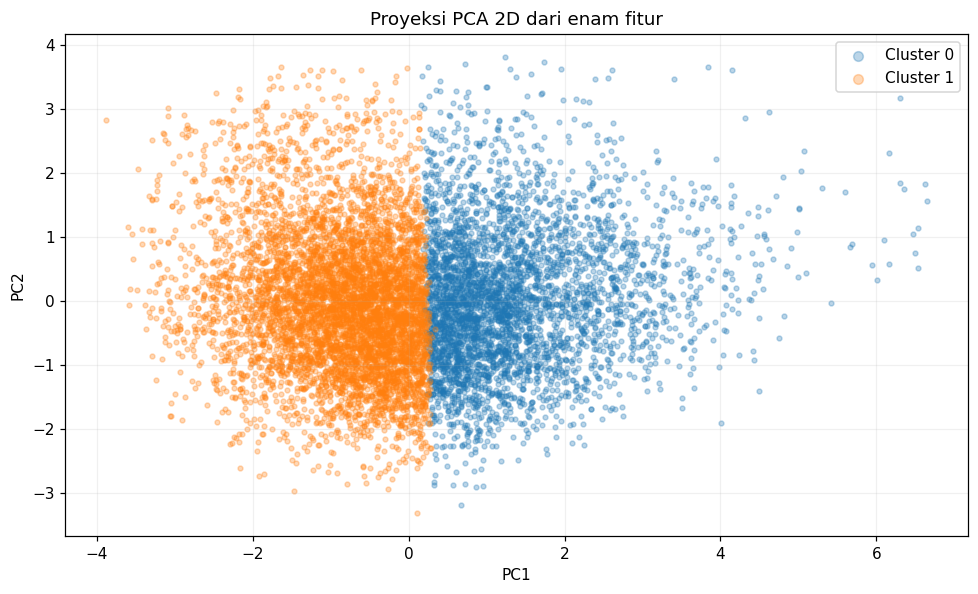

ANALISIS PCA: dua komponen menjelaskan 52.78 % variasi total fitur standar.
PCA bukan dasar pengelompokan pada notebook ini, melainkan visualisasi alternatif dari label model 6 fitur.


In [15]:
# Visualisasi 7 — PCA 2D, hanya untuk interpretasi/pemetaan visual
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(9, 5.5))
for c in sorted(gempa['cluster'].unique()):
    mask = (gempa['cluster'] == c).to_numpy()
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1], s=10, alpha=0.30, label=f'Cluster {c}')
ax.set_title('Proyeksi PCA 2D dari enam fitur')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.legend(markerscale=2); ax.grid(alpha=0.18); plt.tight_layout(); plt.show()

print('ANALISIS PCA: dua komponen menjelaskan', round(pca.explained_variance_ratio_.sum()*100, 2), '% variasi total fitur standar.')
print('PCA bukan dasar pengelompokan pada notebook ini, melainkan visualisasi alternatif dari label model 6 fitur.')

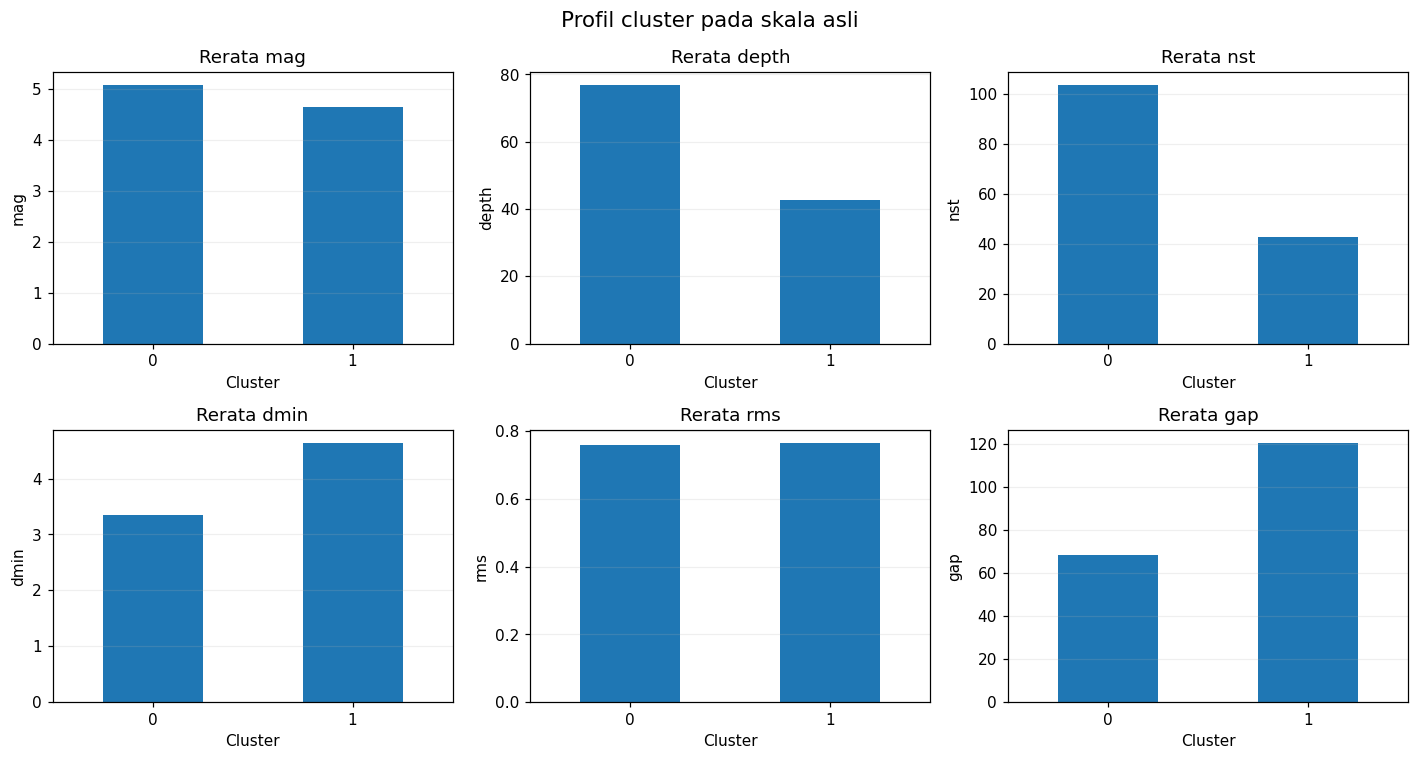

ANALISIS PROFIL RATA-RATA:
- mag: rerata tertinggi cluster 0 (5.077); terendah cluster 1 (4.639).
- depth: rerata tertinggi cluster 0 (76.980); terendah cluster 1 (42.647).
- nst: rerata tertinggi cluster 0 (103.715); terendah cluster 1 (42.783).
- dmin: rerata tertinggi cluster 1 (4.634); terendah cluster 0 (3.352).
- rms: rerata tertinggi cluster 1 (0.765); terendah cluster 0 (0.758).
- gap: rerata tertinggi cluster 1 (120.583); terendah cluster 0 (68.419).
Bandingkan semua fitur bersama-sama, bukan menyimpulkan hanya dari satu grafik.


In [16]:
# Visualisasi 8 — rata-rata setiap fitur berdasarkan cluster
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES):
    profil[col].plot(kind='bar', ax=ax)
    ax.set_title('Rerata ' + col)
    ax.set_xlabel('Cluster'); ax.set_ylabel(col)
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Profil cluster pada skala asli', fontsize=14)
plt.tight_layout(); plt.show()

print('ANALISIS PROFIL RATA-RATA:')
for col in FEATURES:
    hi = int(profil[col].idxmax())
    lo = int(profil[col].idxmin())
    print(f'- {col}: rerata tertinggi cluster {hi} ({profil.loc[hi,col]:.3f}); terendah cluster {lo} ({profil.loc[lo,col]:.3f}).')
print('Bandingkan semua fitur bersama-sama, bukan menyimpulkan hanya dari satu grafik.')

## Langkah 7 — Integrasi dengan dashboard Streamlit

Notebook ini untuk *eksperimen dan dokumentasi kode*; **dashboard interaktif** dijalankan dari berkas `app.py` yang ada di paket ZIP, bukan dari notebook. Dashboard mencakup:

- Ringkasan data, statistik dan distribusi fitur serta analisisnya.
- Heatmap korelasi dan interpretasinya.
- Slider **K=2–8** dan pilihan fitur pada scatter plot.
- Grafik Elbow, Silhouette, profil mean setiap cluster.
- Ekspor dataset hasil clustering.

Di VS Code, buka folder proyek dan jalankan perintah:

```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

Jika dijalankan di Google Colab, **notebook dapat dipakai untuk analisis**, sedangkan dashboard paling mudah dijalankan dari VS Code atau dideploy melalui Streamlit Community Cloud setelah upload ke GitHub.

## Langkah 8 — Menyimpan dataset dan kesimpulan

Dataset hasil disimpan ke `hasil_notebook/Nama_Test3_ClusteringK-Means.csv` dengan kolom `id`, enam fitur hasil standardisasi, dan `cluster`. Kode berikut juga menghasilkan ringkasan cluster dan tabel evaluasi. Berkas `CSV` adalah untuk pengumpulan data terstandardisasi; interpretasi rerata harus memakai skala asli.

In [17]:
# Ekspor — hasil standardisasi + cluster
OUT = Path.cwd() / 'hasil_notebook'
OUT.mkdir(parents=True, exist_ok=True)
standar_hasil = X.add_suffix('_scaled').copy()
standar_hasil.insert(0, 'id', gempa['id'].values)
standar_hasil['cluster'] = gempa['cluster'].values

csv_out = OUT / 'Nama_Test3_ClusteringK-Means.csv'
standar_hasil.to_csv(csv_out, index=False, float_format='%.8f')
ringkasan_cluster.to_csv(OUT / 'ringkasan_cluster.csv')
evaluasi.to_csv(OUT / 'evaluasi_kmeans.csv', index=False)

print('✅ CSV terstandardisasi:', csv_out.resolve())
print('✅ Profil klaster:', (OUT / 'ringkasan_cluster.csv').resolve())
print('✅ Evaluasi K:', (OUT / 'evaluasi_kmeans.csv').resolve())
print('\n5 data pertama yang diekspor:')
display(standar_hasil.head())

print('\nKESIMPULAN PRAKTIKUM')
print(f'1. Sebanyak {len(gempa):,} kejadian gempa dianalisis dengan {len(FEATURES)} fitur numerik.')
print(f'2. Dalam rentang K=2–8, Silhouette tertinggi ada pada K={K_OPTIMAL}, skor {best_score:.4f}.')
print(f'3. Model yang ditampilkan saat ini menggunakan K={K_PILIHAN} dengan inertia {model_final.inertia_:.2f}.')
print('4. Perbedaan profil cluster dapat diamati melalui tabel rata-rata dan visualisasi.')
print('5. Hasil ini bersifat eksploratif dan tidak dapat digunakan untuk memprediksi gempa/tsunami.')

✅ CSV terstandardisasi: /Users/mochammadmarillivio/Downloads/Praktikum_Clustering_KMeans /hasil_notebook/Nama_Test3_ClusteringK-Means.csv
✅ Profil klaster: /Users/mochammadmarillivio/Downloads/Praktikum_Clustering_KMeans /hasil_notebook/ringkasan_cluster.csv
✅ Evaluasi K: /Users/mochammadmarillivio/Downloads/Praktikum_Clustering_KMeans /hasil_notebook/evaluasi_kmeans.csv

5 data pertama yang diekspor:


,id,mag_scaled,depth_scaled,nst_scaled,dmin_scaled,rms_scaled,gap_scaled,cluster
0,us6000u20i,-0.849468,0.268116,-1.025674,0.643756,-0.429774,0.550224,1
1,us6000u20g,-0.304831,-0.823372,0.254027,-0.501202,-0.290141,-0.901871,0
2,us6000u207,1.329082,-0.823372,-0.597110,3.059245,1.245818,-0.878066,0
3,us6000u1zh,-0.304831,-0.823372,-0.597110,-0.348671,0.175301,0.954906,1
4,us6000u1zc,-0.304831,-0.823372,-0.401111,0.083728,0.873464,0.764468,1



KESIMPULAN PRAKTIKUM
1. Sebanyak 9,998 kejadian gempa dianalisis dengan 6 fitur numerik.
2. Dalam rentang K=2–8, Silhouette tertinggi ada pada K=2, skor 0.2050.
3. Model yang ditampilkan saat ini menggunakan K=2 dengan inertia 47685.55.
4. Perbedaan profil cluster dapat diamati melalui tabel rata-rata dan visualisasi.
5. Hasil ini bersifat eksploratif dan tidak dapat digunakan untuk memprediksi gempa/tsunami.


---
### Checklist laporan dan pengumpulan

- [x] **Langkah 1–2:** impor, ringkasan, tipe data, missing, histogram, boxplot, korelasi.
- [x] **Langkah 3:** imputasi, transformasi, winsorisasi dan standardisasi.
- [x] **Langkah 4–5:** K-Means, K optimal, inertia, Silhouette, profil cluster.
- [x] **Langkah 6:** scatter dua fitur, PCA, Elbow, Silhouette, bar plot mean.
- [x] **Langkah 7:** dashboard Streamlit di `app.py`.
- [x] **Langkah 8:** notebook ini menyediakan narasi, evaluasi, kesimpulan, dan ekspor hasil untuk laporan `.docx`.

**Reproduksibilitas:** `random_state=42`, `n_init=10`, `max_iter=300`, Silhouette pada sampel acak tetap 1.200 baris. Perubahan pada input, library, atau K dapat mengubah label serta hasil numerik. Label `cluster` hanyalah indeks dan tidak memiliki ranking risiko.